In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
import numpy as np
import scipy.io
import pandas as pd

# Nonlinear waveguide (Marc's simulation)

In [2]:
# Marc's Data
folder = '../Data/NTT waveguide/'
filename = folder + 'Waveguide Film = 700 nm - 250 nm x Width = 1820 nm Ang = 12 deg Wavelengths = 893-1560nm.mat'

# Load the .mat file
mat_data = scipy.io.loadmat(filename)

lbd_s0 = mat_data['wg']['s'][0,0]['lambda'][0,0] * 1e6
freq_s0 = mat_data['wg']['s'][0,0]['f'][0,0] * 1e-12
neff_s0 = mat_data['wg']['s'][0,0]['neff'][0,0]

lbd_i0 = mat_data['wg']['i'][0,0]['lambda'][0,0] * 1e6
freq_i0 = mat_data['wg']['i'][0,0]['f'][0,0] * 1e-12
neff_i0 = mat_data['wg']['i'][0,0]['neff'][0,0]

lbd_p0 = mat_data['wg']['p'][0,0]['lambda'][0,0] * 1e6
freq_p0 = mat_data['wg']['p'][0,0]['f'][0,0] * 1e-12
neff_p0 = mat_data['wg']['p'][0,0]['neff'][0,0]

# Sampled at width = 1820 nm
w_sample = 1820
neff_p_sample = neff_p0[25]
neff_s_sample = neff_s0[25]

In [3]:
# My Data: Asymmetric components
folder2 = '../wgmodes/Results/OPA_hp1_pad1_lp893_mode4_TFLN_0A_X_df25_Tc30/'
filename2 = folder2 + 'RidgeLN_y_700nm_h_250nm_Wt_1820nm_ang_12deg_lambda_1560nm.mat'
mat_data2 = scipy.io.loadmat(filename2)

lbd_s2 = mat_data2['wg']['lambda_s'][0,0] * 1e6
freq_s2 = mat_data2['wg']['f_s'][0,0] * 1e-12
neff_s2 = mat_data2['wg']['neff_s'][0,0]

lbd_i2 = mat_data2['wg']['lambda_i'][0,0] * 1e6
freq_i2 = mat_data2['wg']['f_i'][0,0]  * 1e-12
neff_i2 = mat_data2['wg']['neff_i'][0,0]

lbd_p2 = mat_data2['wg']['lambda_p'][0,0] * 1e6
freq_p2 = mat_data2['wg']['f_p'][0,0] * 1e-12
neff_p2 = mat_data2['wg']['neff_p'][0,0]

In [4]:
# My Data: Symmetric components
folder3 = '../wgmodes/Results/OPA_hp0_lp893_mode2_TFLN_0S_X_df25_Tc30/'
filename3 = folder3 + 'RidgeLN_y_700nm_h_250nm_Wt_1820nm_ang_12deg_lambda_1560nm.mat'
mat_data3 = scipy.io.loadmat(filename3)

lbd_s3 = mat_data3['wg']['lambda_s'][0,0] * 1e6
freq_s3 = mat_data3['wg']['f_s'][0,0] * 1e-12
neff_s3 = mat_data3['wg']['neff_s'][0,0]

lbd_i3 = mat_data3['wg']['lambda_i'][0,0] * 1e6
freq_i3 = mat_data3['wg']['f_i'][0,0]  * 1e-12
neff_i3 = mat_data3['wg']['neff_i'][0,0]

lbd_p3 = mat_data3['wg']['lambda_p'][0,0] * 1e6
freq_p3 = mat_data3['wg']['f_p'][0,0] * 1e-12
neff_p3 = mat_data3['wg']['neff_p'][0,0]

FileNotFoundError: [Errno 2] No such file or directory: '../wgmodes/Results/OPA_hp0_lp893_mode2_TFLN_0S_X_df25_Tc30/RidgeLN_y_700nm_h_250nm_Wt_1820nm_ang_12deg_lambda_1560nm.mat'

In [4]:
folder_lum = "C:/Users/elaksono/Dropbox/Stanford Courses/Lumerical Simulations/Taper_WG/Modes/"
filename_lum = folder_lum + "disp_data W=1820nm N=4.csv"
mat_data_lum = pd.read_csv(filename_lum).to_numpy()
freq_lum = mat_data_lum[:,0]
lbd_lum = 3e8 / freq_lum * 1e6
neff_lum = mat_data_lum[:,1:]

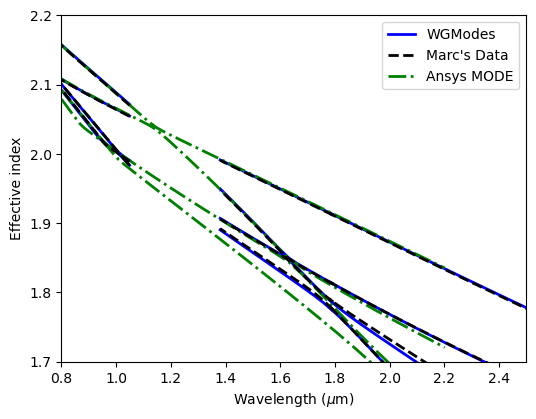

In [9]:
# Effective index
lim_set = True
lbd_vec = (0.8, 2.5)
neff_vec = (1.7, 2.2)
fig, ax = plt.subplots(1, 1, figsize=(6, 4.5))
for i in range(4):    
    ax.plot(lbd_p2[0], neff_p2[:,i], label='p', color = 'blue', linewidth=2)
    ax.plot(lbd_s2[0], neff_s2[:,i], label='s', color = 'blue', linewidth=2)
    ax.plot(lbd_i2[0], neff_i2[:,i], label='i', color = 'blue', linewidth=2)
    
    # ax.plot(lbd_p3[0], neff_p3[:,i], label='p', color = 'red')    
    # ax.plot(lbd_s3[0], neff_s3[:,i], label='p', color = 'red')
    # ax.plot(lbd_i3[0], neff_i3[:,i], label='i', color = 'red')

ax.plot(lbd_lum, neff_lum, label='lumerical', color = 'green', linestyle='-.', linewidth=2)

for i in range(neff_p0.shape[1]):   
    ax.plot(lbd_p0[0], neff_p0[:,i], label='p', color = 'black', linestyle='--', linewidth=2)
    ax.plot(lbd_s0[0], neff_s0[:,i], label='s', color = 'black', linestyle='--', linewidth=2)
    ax.plot(lbd_i0[0], neff_i0[:,i], label='i', color = 'black', linestyle='--', linewidth=2)

custom_lines = [
    Line2D([0], [0], color='blue', lw=2),
    Line2D([0], [0], color='black', linestyle='--', lw=2),
    Line2D([0], [0], color='green', linestyle='-.', lw=2)
]

ax.legend(custom_lines, ['WGModes', 'Marc\'s Data', 'Ansys MODE'])

if lim_set:
    ax.set_xlim(lbd_vec[0],lbd_vec[1])
    ax.set_ylim(neff_vec[0],neff_vec[1])
ax.set_xlabel(r'Wavelength ($\mu$m)')
ax.set_ylabel(r'Effective index')

plt.savefig(f'./Plots/TFLN_neff_vs_lbd_{lbd_vec[0]}_{lbd_vec[1]}.png')

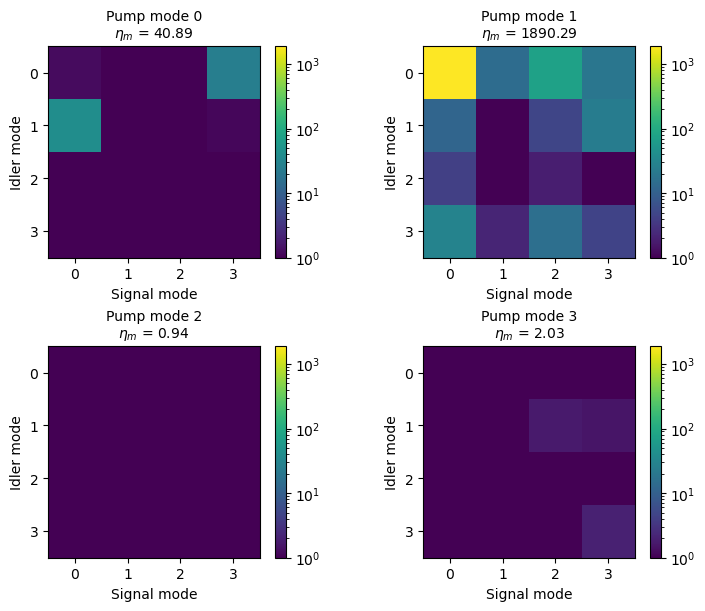

In [11]:
# Effective nonlinear coefficient
fig, ax = plt.subplots(2, 2, figsize=(7.5, 6.0), constrained_layout=True)
id_freq = 25
eta_dat0 = mat_data['wg']['s'][0,0]['eta'][0,0][id_freq]
eta_max0 = np.max(eta_dat0)

for (i,j) in [(0,0), (0,1), (1,0), (1,1)]:
    k = 2*i + j
    eta = eta_dat0[k]
    im0 = ax[i][j].imshow(eta, norm = LogNorm(vmin = 1.0, vmax = eta_max0), cmap = 'viridis')
    ax[i][j].set_title(f'Pump mode {k}\n$\eta_m$ = {np.max(eta):.2f}', fontsize = 10)
    ax[i][j].set_xlabel(f'Signal mode')
    ax[i][j].set_ylabel(f'Idler mode')
    fig.colorbar(im0, ax = ax[i][j])

plt.show()

# Waveguide of various widths

In [5]:
opa_folder = "C:/Users/elaksono/Dropbox/Stanford Courses/EO Comb/wgmodes/Results/OPA_fullE_hp1_pad1_lp893_mode4_TFLN_0A_X_df5_Tc30/"
opa_widths = np.arange(600, 1901, 20)
# opa_widths = np.sort(np.append(opa_widths, np.arange(650, 1051, 100)))
opa_files = [opa_folder + f"RidgeLN_y_700nm_h_250nm_Wt_{wt}nm_ang_12deg_lambda_1560nm.mat" for wt in opa_widths]

In [92]:
opa_files[40]

'C:/Users/elaksono/Dropbox/Stanford Courses/EO Comb/wgmodes/Results/OPA_fullE_hp1_pad1_lp893_mode4_TFLN_0A_X_df5_Tc30/RidgeLN_y_700nm_h_250nm_Wt_1400nm_ang_12deg_lambda_1560nm.mat'

In [6]:
test_mat = scipy.io.loadmat(opa_files[1])['wg']

# (Pump, Signal, Idler) wavelengths and frequencies
lbd_p = test_mat['lambda_p'][0,0] * 1e6
freq_p = test_mat['f_p'][0,0] * 1e-12

lbd_s = test_mat['lambda_s'][0,0] * 1e6
freq_s = test_mat['f_s'][0,0] * 1e-12

lbd_i = test_mat['lambda_i'][0,0]* 1e6
freq_i = test_mat['f_i'][0,0] * 1e-12

# Make a list of neff
neff_s = [test_mat['neff_s'][0,0]]
neff_i = [test_mat['neff_i'][0,0]]
neff_p = [test_mat['neff_p'][0,0]]

# Power ratio Exy
r_power_p = [test_mat['Exy_ratio_p'][0,0]]
r_power_s = [test_mat['Exy_ratio_s'][0,0]]
r_power_i = [test_mat['Exy_ratio_i'][0,0]]

# eta_s
f_id = 1
# eta_s = [test_mat['eta_s'][0,0][f_id]]
for file in opa_files[1:]:
    test_mat = scipy.io.loadmat(file)['wg']
    
    neff_s.append(test_mat['neff_s'][0,0])
    neff_i.append(test_mat['neff_i'][0,0])
    neff_p.append(test_mat['neff_p'][0,0])
    
    r_power_p.append(test_mat['Exy_ratio_p'][0,0])
    r_power_s.append(test_mat['Exy_ratio_s'][0,0])
    r_power_i.append(test_mat['Exy_ratio_i'][0,0])
    # eta_s.append(test_mat['eta_s'][0,0][f_id])

neff_s = np.array(neff_s)
neff_i = np.array(neff_i)
neff_p = np.array(neff_p)

r_power_p = np.array(r_power_p)
r_power_s = np.array(r_power_s)
r_power_i = np.array(r_power_i)

neff_p_sort = np.sort(neff_p, axis = 2)[::,::,::-1]

# eta_s = np.array(eta_s)

In [9]:
# Effective nonlinear coefficient
# fig, ax = plt.subplots(2, 2, figsize=(7.5, 6.0), constrained_layout=True)
# id_width = -2

# for (i,j) in [(0,0), (0,1), (1,0), (1,1)]:
#     k = 2*i + j
#     eta_plot = eta_s[id_width]
#     eta_plot_max = np.max(eta_plot)
    
#     eta = eta_plot[k]
#     im = ax[i][j].imshow(eta, norm = LogNorm(vmin = 1.0, vmax = eta_plot_max), cmap = 'viridis')
#     ax[i][j].set_title(f'Pump mode {k}\n$\eta_m$ = {np.max(eta):.2f}', fontsize = 10)
#     ax[i][j].set_xlabel(f'Signal mode')
#     ax[i][j].set_ylabel(f'Idler mode')
#     fig.colorbar(im, ax = ax[i][j])

# plt.show()

In [106]:
neff_s[:,1,0]

array([1.89803168, 1.89803168, 1.89961519, 1.90147525, 1.90304029,
       1.90486946, 1.90640101, 1.90818389, 1.9096708 , 1.91139626,
       1.91283073, 1.91449122, 1.91586818, 1.91745904, 1.9187756 ,
       1.92029442, 1.92154939, 1.92299553, 1.92418897, 1.92556306,
       1.92669597, 1.9279996 , 1.92907365, 1.93030905, 1.93132637,
       1.93249621, 1.9334592 , 1.93456643, 1.93547767, 1.93652536,
       1.93738749, 1.93837878, 1.93919447, 1.94013246, 1.94090431,
       1.94179205, 1.94252262, 1.94336305, 1.94405477, 1.9448507 ,
       1.94550592, 1.94626005, 1.94688097, 1.94759583, 1.94818456,
       1.94886256, 1.94942106, 1.95006445, 1.95059459, 1.95120549,
       1.95170899, 1.95228939, 1.95276788, 1.95331963, 1.95377464,
       1.95429947, 1.9547324 , 1.95523194, 1.95564413, 1.95611988,
       1.95651257, 1.95696594, 1.95734027, 1.95777259, 1.95812964,
       1.95854213])

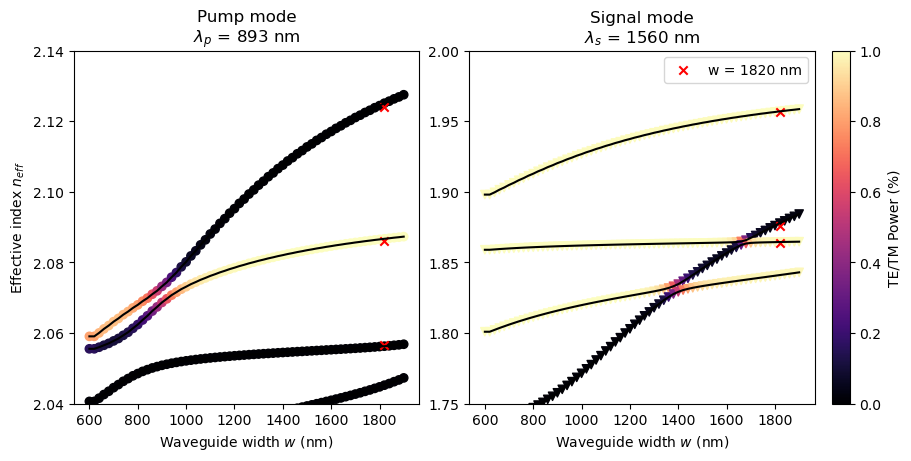

In [12]:
w_sample = 1820
sample_points = 3
norm = Normalize(vmin=0, vmax=1)

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5), constrained_layout=True)
ax[0].plot(opa_widths, neff_p_sort[:,1,:], color = 'k')
for i in range(4):
    ax[0].scatter(opa_widths, neff_p[:,1,i], c = r_power_p[:,1,i], cmap = 'magma', marker = 'o', norm = norm)
    
ax[0].scatter(w_sample * np.ones(sample_points), neff_p_sample[:sample_points], color = 'red', label = 'w = 1820 nm', marker = 'x')
ax[0].set_title('Pump mode\n$\lambda_p$ = 893 nm')
ax[0].set_xlabel(r'Waveguide width $w$ (nm)')
ax[0].set_ylabel(r'Effective index $n_{eff}$')

ax[1].plot(opa_widths, neff_s[:,1,:], color = 'k')
for i in range(4):
    im = ax[1].scatter(opa_widths, neff_s[:,1,i], c = r_power_s[:,1,i], cmap = 'magma', marker = 'v', norm = norm)

ax[1].scatter(w_sample * np.ones(sample_points), neff_s_sample[:sample_points], color = 'red', label = 'w = 1820 nm', marker = 'x')
ax[1].set_title('Signal mode\n$\lambda_s$ = 1560 nm')
ax[1].set_xlabel(r'Waveguide width $w$ (nm)')
ax[1].legend()

ax[0].set_ylim(2.04, 2.14)
ax[1].set_ylim(1.75, 2.00)

plt.colorbar(im, ax = ax[1], cmap = 'magma', label = 'TE/TM Power (%)')

plt.savefig('./Plots/TFLN_neff_vs_width.png')

plt.show()